# Extended data exploration
The previous data exploration showed the temperature over time.<br>
I would like to expand this by looking at the seasonal trends instead of the temporal trends.<br>
This is because the country data is per month, and combining all data from over the world will mix the seasons. 

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
df_city = pd.read_parquet("ClimateData_clean/city_data.parquet")
df_city["year"] = df_city.dt.dt.year
df_city["month"] = df_city.dt.dt.month

In [24]:
northern_hemisphere_cond = df_city["Latitude"].str.endswith("N")
df_city["shifted_temp"] = np.where(
    northern_hemisphere_cond, 
    df_city["AverageTemperatureCleaned"],                             
    df_city["AverageTemperatureCleaned"].shift(6)                             
    )

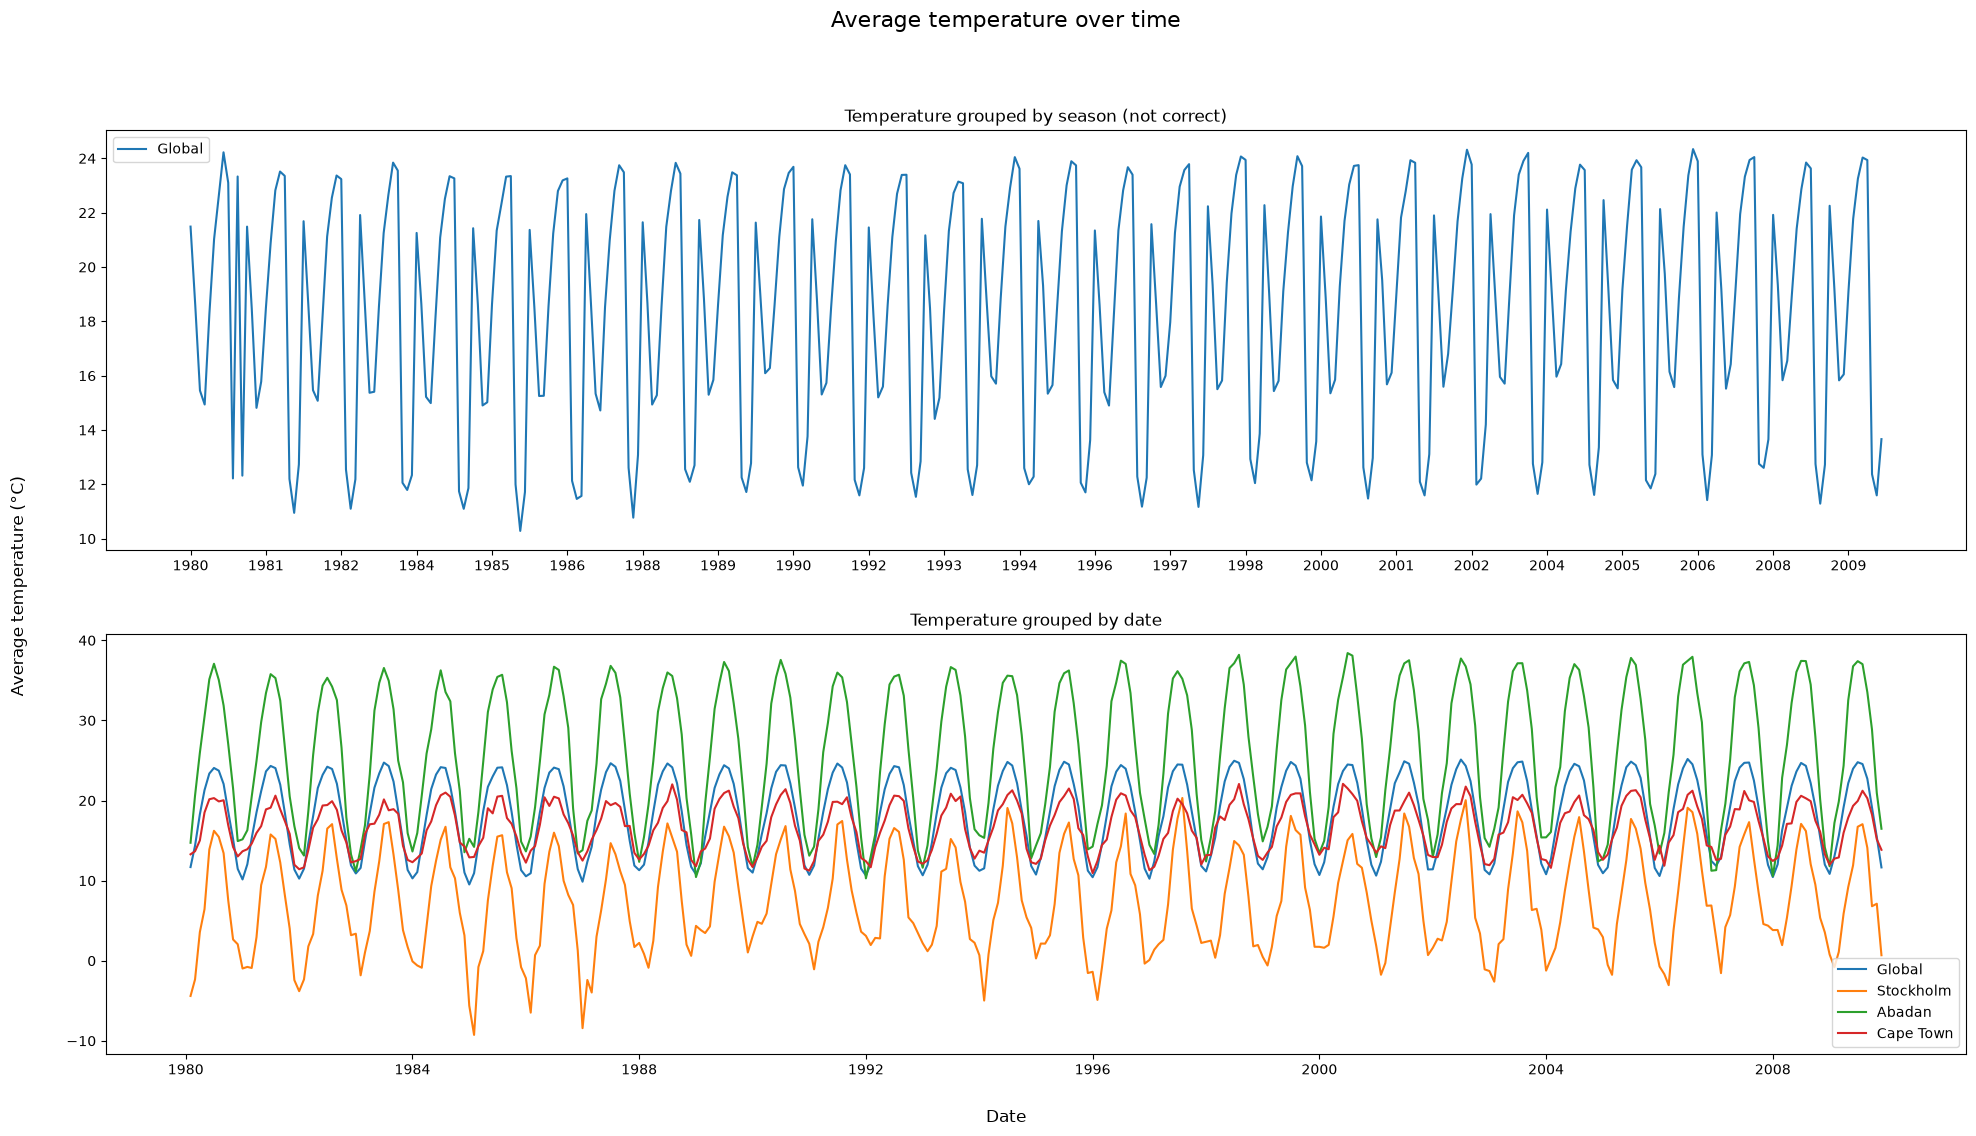

In [29]:
min_date = "1980-01-01"
max_date = "2010-01-01"

df_city_filter_date = df_city[
    (df_city["dt"] > min_date)
    & (df_city["dt"] < max_date)
]

df_city_sorted = df_city_filter_date.sort_values(["City", "Country", "dt"])

# Temperature per city/global
df_city_vis_global_season = df_city_sorted[["year_season", "shifted_temp"]].groupby(["year_season"]).mean()
df_city_vis_global_dates = df_city_sorted[["dt", "shifted_temp"]].groupby(["dt"]).mean()
amsterdam_temps = df_city_sorted[df_city_sorted["City"] == "Amsterdam"]["shifted_temp"]
stockholm_temps = df_city_sorted[df_city_sorted["City"] == "Stockholm"]["shifted_temp"]
madrid_temps = df_city_sorted[df_city_sorted["City"] == "Madrid"]["shifted_temp"]
kaapstad_temps = df_city_sorted[df_city_sorted["City"] == "Cape Town"]["shifted_temp"]
sydney_temps = df_city_sorted[df_city_sorted["City"] == "Sydney"]["shifted_temp"]
abadan_temps = df_city_sorted[df_city_sorted["City"] == "Abadan"]["shifted_temp"]

year_seasons = df_city_sorted["year_season"].unique()
years = df_city_sorted["year"].unique()
dates = df_city_sorted["dt"].unique()

fig, ax = plt.subplots(2,1, figsize=(24,12))
fig.suptitle("Average temperature over time", fontsize=16)
fig.supylabel("Average temperature (°C)", x=0.085)
fig.supxlabel("Date", y=0.05)

# Upper subplot
ax[0].plot(df_city_vis_global_season.index, df_city_vis_global_season["shifted_temp"], label="Global")

tick_positions = range(0, len(year_seasons), 16)
tick_labels = [year_seasons[i].split("_")[0] for i in tick_positions]
ax[0].set_xticks(tick_positions)
ax[0].set_xticklabels(tick_labels)
ax[0].legend()
ax[0].set_title("Temperature grouped by season (not correct)")


# Lower subplot
ax[1].plot(dates, df_city_vis_global_dates, label="Global")
# ax[1].plot(dates, amsterdam_temps, label="Amsterdam")
ax[1].plot(dates, stockholm_temps, label="Stockholm")
ax[1].plot(dates, abadan_temps, label="Abadan")
# ax[1].plot(dates, madrid_temps, label="Madrid")
ax[1].plot(dates, kaapstad_temps, label="Cape Town")
# ax[1].plot(dates, sydney_temps, label="Sydney")

ax[1].legend()
ax[1].set_title("Temperature grouped by date")

plt.show()